In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
#Loading the data
df = pd.read_csv("merged_music_cleaned.csv")
print(df.shape)

(113549, 43)


In [3]:
# Preparing the data
df["explicit"] = df["explicit"].astype(int)
df["artist"] = df["artists"].fillna("unknown").str.split(";").str[0].str.strip()

title = df["track_name"].fillna("").str.lower()
title = title.str.replace(r"\s*[\(\[\-].*$", "", regex=True).str.strip()   # drop "(Remastered)", "- Acoustic", ...
df["song_key"] = df["artist"].str.lower() + "|" + title

df["genre_code"] = df["track_genre"].astype("category").cat.codes

In [4]:
# Split 
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(df, groups=df["song_key"]))

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

print("Training rows:", len(train), " Test rows:", len(test))
print("Songs in both sets:", len(set(train["song_key"]) & set(test["song_key"])))

Training rows: 91120  Test rows: 22429
Songs in both sets: 0


In [5]:
K = 10
global_mean = train["popularity"].mean()

artist_sum = train.groupby("artist")["popularity"].sum()
artist_count = train.groupby("artist")["popularity"].count()

# Training rows: artist totals minus this song's own rows
song_sum = train.groupby("song_key")["popularity"].transform("sum")
song_count = train.groupby("song_key")["popularity"].transform("count")
s = train["artist"].map(artist_sum) - song_sum
c = train["artist"].map(artist_count) - song_count
train["artist_pop"] = (s + K * global_mean) / (c + K)
train["artist_count"] = c

# Test rows: use the full training statistics
s = test["artist"].map(artist_sum).fillna(0)
c = test["artist"].map(artist_count).fillna(0)
test["artist_pop"] = (s + K * global_mean) / (c + K)
test["artist_count"] = c

In [6]:
#Inputs to the model
features = ["artist_pop", "artist_count", "genre_code",
            "duration_ms", "explicit", "danceability", "energy",
            "loudness", "acousticness", "instrumentalness"]

X_train, y_train = train[features], train["popularity"]
X_test, y_test = test[features], test["popularity"]

def evaluate(name, y_true, y_pred):
    return {"Model": name,
            "MAE": round(mean_absolute_error(y_true, y_pred), 3),
            "RMSE": round(np.sqrt(mean_squared_error(y_true, y_pred)), 3),
            "R2": round(r2_score(y_true, y_pred), 3)}

results = []

## Baselines
1. Predict the training average for every song.
2. Predict the average popularity of the song's genre.

In [7]:
results.append(evaluate("Mean baseline", y_test, np.full(len(y_test), global_mean)))

genre_mean = train.groupby("track_genre")["popularity"].mean()
results.append(evaluate("Genre-mean baseline", y_test,
                        test["track_genre"].map(genre_mean).fillna(global_mean)))
pd.DataFrame(results)

,Model,MAE,RMSE,R2
0,Mean baseline,18.658,22.162,-0.000
1,Genre-mean baseline,13.997,19.234,0.247


## Proposed model: gradient boosting + artist features
- `categorical_features` tells the model that `genre_code` is a category, not a number.
- Small grid search with 5-fold `GroupKFold` (grouped by song), scored by MAE.

In [9]:
is_categorical = [f == "genre_code" for f in features]

hgb = HistGradientBoostingRegressor(categorical_features=is_categorical, max_iter=800,
                                    l2_regularization=1.0, random_state=42)

param_grid = {
    "learning_rate": [0.03, 0.1],
    "max_leaf_nodes": [31, 63],
    "min_samples_leaf": [20, 50],
}

search = GridSearchCV(hgb, param_grid, cv=GroupKFold(n_splits=5),
                      scoring="neg_mean_absolute_error", n_jobs=-1)
search.fit(X_train, y_train, groups=train["song_key"])

print("Best parameters:", search.best_params_)
print("Best cross-validation MAE:", round(-search.best_score_, 3))

model = search.best_estimator_
y_pred = model.predict(X_test)
results.append(evaluate("Proposed: HGB + artist features", y_test, y_pred))

Best parameters: {'learning_rate': 0.03, 'max_leaf_nodes': 63, 'min_samples_leaf': 50}
Best cross-validation MAE: 9.889


## Results

In [10]:
results_df = pd.DataFrame(results).set_index("Model")
results_df

,MAE,RMSE,R2
Model,,,
Mean baseline,18.658,22.162,-0.000
Genre-mean baseline,13.997,19.234,0.247
Proposed: HGB + artist features,10.255,16.162,0.468


In [11]:
# Known artists vs new artists (artists not in the training data)
new_artist = (test["artist_count"] == 0).to_numpy()
print("New-artist rows in the test set: %.1f%%" % (100 * new_artist.mean()))
pd.DataFrame([evaluate("Known artists", y_test[~new_artist], y_pred[~new_artist]),
              evaluate("New artists", y_test[new_artist], y_pred[new_artist])]).set_index("Model")

New-artist rows in the test set: 10.1%


,MAE,RMSE,R2
Model,,,
Known artists,10.024,16.004,0.484
New artists,12.312,17.505,0.269


In [12]:
# Error analysis: average error by actual popularity range
bands = pd.cut(y_test, bins=[-1, 0, 20, 40, 60, 80, 100],
               labels=["0", "1-20", "21-40", "41-60", "61-80", "81-100"])
errors = pd.DataFrame({"band": bands, "abs_error": np.abs(y_test - y_pred)})
errors.groupby("band", observed=True)["abs_error"].agg(["mean", "count"]).round(2)

,mean,count
band,,
0,21.78,3003
1-20,9.14,3550
21-40,4.97,6721
41-60,7.30,6504
61-80,18.31,2427
81-100,30.45,224


## 10. Plots

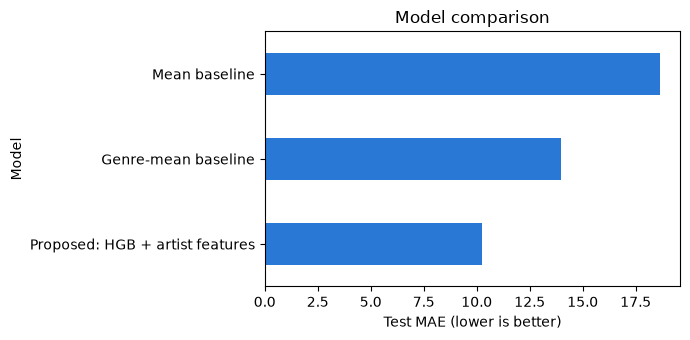

In [13]:
results_df["MAE"].sort_values().plot(kind="barh", figsize=(7, 3.5), color="#2a78d6")
plt.xlabel("Test MAE (lower is better)")
plt.title("Model comparison")
plt.tight_layout()
plt.show()

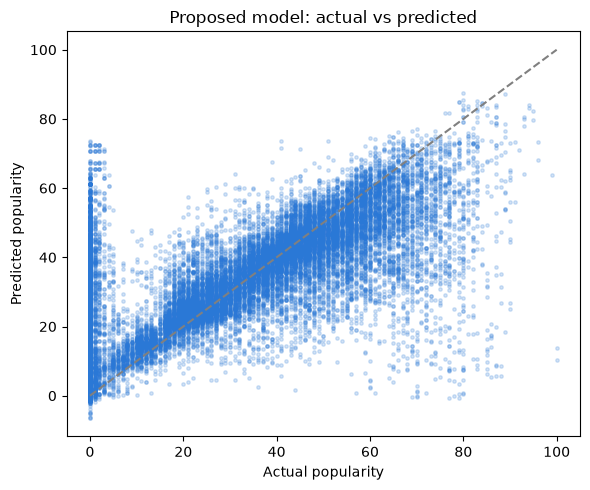

In [14]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, s=6, alpha=0.2, color="#2a78d6")
plt.plot([0, 100], [0, 100], "--", color="grey")
plt.xlabel("Actual popularity")
plt.ylabel("Predicted popularity")
plt.title("Proposed model: actual vs predicted")
plt.tight_layout()
plt.show()

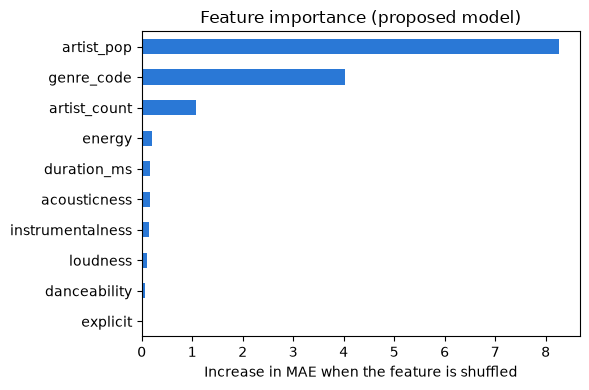

In [15]:
# Permutation importance: how much the error grows when one feature is randomly shuffled
sample = X_test.sample(5000, random_state=42)
perm = permutation_importance(model, sample, y_test.loc[sample.index],
                              scoring="neg_mean_absolute_error", n_repeats=5, random_state=42)
importance = pd.Series(perm.importances_mean, index=features).sort_values()

importance.plot(kind="barh", figsize=(6, 4), color="#2a78d6")
plt.xlabel("Increase in MAE when the feature is shuffled")
plt.title("Feature importance (proposed model)")
plt.tight_layout()
plt.show()

In [16]:
import joblib
joblib.dump(model, "hgb_artist_model.pkl")

['hgb_artist_model.pkl']